# IE7615 – Discriminative Project, Milestone 3
## Object detection with tight bounding boxes (YOLOv8)

Aditi Kulkarni · Sakshi Pawar · Aditya Sai Kumar Kusetti · Hemanth Mareedu

In our first version every label box covered the whole photo tile, because we only knew which grid cell each photo went into. Feedback was that the box should sit on the object itself, even when the object is surrounded by other items. So in this version:

1. We get a real box around the object in every single-object photo, using Grounding DINO (a pretrained open-vocabulary detector) prompted with the object's name from the Object ID sheet.
2. We check those boxes, fix the prompt for any object it struggles with, and drop photos where it isn't confident.
3. We build the grid images as before, but now each label is the object's own box moved into its grid position.
4. We train YOLOv8s on that.

Runtime: Colab, T4 GPU.

### Setup

In [ ]:
!nvidia-smi
!pip install -q ultralytics
!pip install -q -U transformers

Sun Oct 18 22:19:44 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Data

In [ ]:
import os, glob, shutil, subprocess, re, json, random
from pathlib import Path
from PIL import Image, ImageEnhance, ImageDraw
import matplotlib.pyplot as plt

DRIVE_DATASET = "/content/drive/MyDrive/IE7615 Deep Learning for AI"   # Drive shortcut to the merged dataset
LOCAL = "/content/data"
RESULTS = Path("/content/drive/MyDrive/IE7615_M3_results")             # new folder, older results are left alone
RESULTS.mkdir(parents=True, exist_ok=True)

os.makedirs(LOCAL, exist_ok=True)
if os.path.exists(DRIVE_DATASET) and not glob.glob(f"{LOCAL}/*"):
    subprocess.run(["cp", "-rL", DRIVE_DATASET, LOCAL], check=True)   # -L copies the real files, not the shortcut

SRC, n = None, 0
for d, subs, _ in os.walk(LOCAL):
    k = sum(s.startswith("images_") for s in subs)
    if k > n:
        SRC, n = d, k
print(SRC, "->", n, "class folders")

/content/data/IE7615 Deep Learning for AI -> 73 class folders


In [ ]:
TILE = 224
SEED = 42
is_bg = re.compile(r"(?:^|[_\-\s])(bg|background)(?:[_\-\s\d.]|$)", re.I)

folders = sorted(p for p in Path(SRC).iterdir() if p.is_dir() and p.name.startswith("images_"))
classes, files, n_bg = [], [], 0
for folder in folders:
    imgs = []
    for f in sorted(folder.iterdir()):
        if f.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
            continue
        if is_bg.search(f.stem):
            n_bg += 1
            continue
        imgs.append(f)
    if imgs:
        classes.append(folder.name.replace("images_", "", 1))
        files.append(imgs)
print(len(classes), "classes |", sum(len(x) for x in files), "images |", n_bg, "background images removed")

def load224(path):
    img = Image.open(path).convert("RGB")
    return img if img.size == (TILE, TILE) else img.resize((TILE, TILE))

73 classes | 6958 images | 385 background images removed


### Object names

Grounding DINO needs a text description of each object to find it in the photo. We took the names from the class Object ID sheet. These are only used for labeling; YOLO is trained and evaluated on the Object IDs.

In [ ]:
# Object names from the class Object ID sheet (used only as prompts for Grounding DINO;
# the model itself still outputs Object IDs). A few were reworded slightly so the detector
# understands them better, e.g. "Clutcher" -> "hair clip", "Pickleball bat" -> "pickleball paddle".
NAMES = {
    "OBJ001": "basketball",
    "OBJ002": "water bottle",
    "OBJ003": "notebook",
    "OBJ004": "toy car",
    "OBJ005": "computer mouse",
    "OBJ006": "capybara toy",
    "OBJ007": "apple",
    "OBJ008": "cat",
    "OBJ009": "marshall speaker",
    "OBJ010": "nike sneakers",
    "OBJ011": "mug",
    "OBJ012": "computer keyboard",
    "OBJ013": "mobile phone",
    "OBJ014": "sunglasses",
    "OBJ015": "water tumbler",
    "OBJ016": "portable ssd",
    "OBJ017": "game controller",
    "OBJ018": "rubiks cube",
    "OBJ019": "potted plant",
    "OBJ020": "airpods case",
    "OBJ021": "toy bunny",
    "OBJ022": "guitar",
    "OBJ023": "bracelet",
    "OBJ024": "plush doll",
    "OBJ025": "watch",
    "OBJ026": "baseball cap",
    "OBJ027": "tennis ball",
    "OBJ028": "banana",
    "OBJ029": "orange",
    "OBJ030": "tennis racket",
    "OBJ031": "uno card box",
    "OBJ032": "sound card",
    "OBJ033": "duck",
    "OBJ034": "table tennis racket",
    "OBJ035": "badminton racket",
    "OBJ036": "pencil case",
    "OBJ037": "candle",
    "OBJ038": "perfume bottle",
    "OBJ039": "scissors",
    "OBJ040": "hair clip",
    "OBJ041": "table fan",
    "OBJ042": "mouth guard case",
    "OBJ043": "swimming goggles",
    "OBJ044": "anime figurine",
    "OBJ045": "wayfarer sunglasses",
    "OBJ046": "smartwatch",
    "OBJ047": "backpack",
    "OBJ048": "wireless power bank",
    "OBJ049": "pickleball paddle",
    "OBJ050": "hairbrush",
    "OBJ051": "tissue",
    "OBJ052": "spoon",
    "OBJ053": "moisturizer",
    "OBJ054": "purse",
    "OBJ055": "scientific calculator",
    "OBJ056": "tote bag",
    "OBJ057": "power bank",
    "OBJ058": "footstool",
    "OBJ059": "comb",
    "OBJ060": "sleep mask",
    "OBJ061": "card wallet",
    "OBJ062": "headphones",
    "OBJ063": "measuring bottle",
    "OBJ064": "projector",
    "OBJ065": "analog watch",
    "OBJ066": "hair oil bottle",
    "OBJ067": "wallet",
    "OBJ068": "neck pillow",
    "OBJ069": "knife",
    "OBJ070": "astronaut projector",
    "OBJ071": "sloth plushie",
    "OBJ072": "dog",
    "OBJ073": "bowl"
}

# Item names as written in the sheet, shown next to the Object ID in every prediction
ITEM = {
    "OBJ001": "Basketball",
    "OBJ002": "Water Bottle",
    "OBJ003": "Notebook",
    "OBJ004": "Toy Car",
    "OBJ005": "Computer Mouse",
    "OBJ006": "Capybara Toy",
    "OBJ007": "Apple",
    "OBJ008": "Cat",
    "OBJ009": "Marshall Speaker",
    "OBJ010": "Nike Sneakers",
    "OBJ011": "Mug",
    "OBJ012": "Computer Keyboard",
    "OBJ013": "Mobile Phone",
    "OBJ014": "Sunglasses",
    "OBJ015": "Water Tumbler",
    "OBJ016": "Sandisk Portable SSD",
    "OBJ017": "Controller",
    "OBJ018": "Rubiks Cube",
    "OBJ019": "Plant",
    "OBJ020": "Airpod",
    "OBJ021": "Toy Bunny",
    "OBJ022": "Guitar",
    "OBJ023": "Bracelet",
    "OBJ024": "Plush Doll",
    "OBJ025": "Watch",
    "OBJ026": "Red Sox Cap",
    "OBJ027": "Tennis Ball",
    "OBJ028": "Banana",
    "OBJ029": "Orange",
    "OBJ030": "Tennis Racket",
    "OBJ031": "UNO Card Box",
    "OBJ032": "Sound Card",
    "OBJ033": "Duck",
    "OBJ034": "Table Tennis Racket",
    "OBJ035": "Badminton Racket",
    "OBJ036": "Pencil Case",
    "OBJ037": "Candle",
    "OBJ038": "Perfume Bottle",
    "OBJ039": "Scissors",
    "OBJ040": "Clutcher",
    "OBJ041": "Table Fan",
    "OBJ042": "Mouth Guard Case",
    "OBJ043": "Swimming Goggles",
    "OBJ044": "Anime Figurine",
    "OBJ045": "Wayfarer Sunglasses",
    "OBJ046": "iWatch",
    "OBJ047": "Backpack",
    "OBJ048": "Wireless Powerbank",
    "OBJ049": "Pickleball Bat",
    "OBJ050": "Hairbrush",
    "OBJ051": "Tissue",
    "OBJ052": "Spoon",
    "OBJ053": "Moisturizer",
    "OBJ054": "Purse",
    "OBJ055": "Scientific Calculator",
    "OBJ056": "Trader Joe's Bag",
    "OBJ057": "Power Bank",
    "OBJ058": "Footstool",
    "OBJ059": "Comb",
    "OBJ060": "Sleep Mask",
    "OBJ061": "Card Wallet",
    "OBJ062": "Headphones",
    "OBJ063": "Measuring Bottle",
    "OBJ064": "RGB Projector",
    "OBJ065": "Analog Watch",
    "OBJ066": "Hair Oil",
    "OBJ067": "Men's Wallet",
    "OBJ068": "Neck Pillow",
    "OBJ069": "Knife",
    "OBJ070": "Astronaut Projector",
    "OBJ071": "Sloth Plushie",
    "OBJ072": "Dog",
    "OBJ073": "Bowl"
}

def display_name(c):
    return f"{c} {ITEM[c]}" if c in ITEM else c

missing = [c for c in classes if c not in NAMES]
print(len(NAMES), "names |", len(missing), "classes without a name:", missing)

73 names | 0 classes without a name: []


In [ ]:
# If an object gets bad boxes, describe it better here and rerun the box cells for it,
# e.g. PROMPT_FIX = {"OBJ057": "blue metal water bottle"}
PROMPT_FIX = {}

def prompt_for(c):
    return PROMPT_FIX.get(c) or NAMES.get(c) or "object"

### Automatic boxes with Grounding DINO

For each photo we ask Grounding DINO for the object's name and keep its most confident box. Results are cached in Drive (`auto_boxes.json`), so this only runs once (about 15–25 min on a T4).

In [ ]:
import torch
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection

device = "cuda" if torch.cuda.is_available() else "cpu"
GD_ID = "IDEA-Research/grounding-dino-tiny"
processor = AutoProcessor.from_pretrained(GD_ID)
# our photos are only 224x224, so 512px input is plenty and keeps memory low on the T4
processor.image_processor.size = {"shortest_edge": 512, "longest_edge": 512}
gd = AutoModelForZeroShotObjectDetection.from_pretrained(GD_ID).to(device).eval()

@torch.no_grad()
def gd_boxes(paths, prompt, bs=4):
    text = prompt.lower().strip().rstrip(".") + "."
    out = {}
    for i in range(0, len(paths), bs):
        chunk = paths[i:i + bs]
        imgs = [load224(p) for p in chunk]
        inputs = processor(images=imgs, text=[text] * len(imgs), return_tensors="pt", padding=True).to(device)
        with torch.autocast("cuda", dtype=torch.float16, enabled=(device == "cuda")):
            res = gd(**inputs)
        sizes = [(TILE, TILE)] * len(imgs)
        try:
            post = processor.post_process_grounded_object_detection(
                res, inputs.input_ids, threshold=0.1, text_threshold=0.1, target_sizes=sizes)
        except TypeError:   # older transformers
            post = processor.post_process_grounded_object_detection(
                res, inputs.input_ids, box_threshold=0.1, text_threshold=0.1, target_sizes=sizes)
        for p, r in zip(chunk, post):
            if len(r["scores"]):
                k = int(r["scores"].argmax())
                x1, y1, x2, y2 = [float(v) for v in r["boxes"][k]]
                out[str(p)] = [max(0, x1), max(0, y1), min(TILE, x2), min(TILE, y2), float(r["scores"][k])]
            else:
                out[str(p)] = None
        del inputs, res
    if device == "cuda":
        torch.cuda.empty_cache()
    return out

CACHE = RESULTS / "auto_boxes.json"
BOXES = json.loads(CACHE.read_text()) if CACHE.exists() else {}

def label_classes(class_list, force=False):
    for n, c in enumerate(class_list, 1):
        cid = classes.index(c)
        todo = [p for p in files[cid] if force or str(p) not in BOXES]
        if todo:
            BOXES.update(gd_boxes(todo, prompt_for(c)))
            CACHE.write_text(json.dumps(BOXES))   # save after every object so progress isn't lost
        print(f"\r{n}/{len(class_list)} {c}", end="")
    print()

label_classes(classes)
print(len(BOXES), "photos have an automatic box")

Loading weights:   0%|          | 0/978 [00:00<?, ?it/s]

73/73 OBJ073
6958 photos have an automatic box


### How good are the boxes?

A photo is kept only if Grounding DINO's confidence is at least `KEEP`. The table lists the objects with the most dropped photos. Those are the ones to look at.

In [ ]:
import pandas as pd
KEEP = 0.30

def summary():
    rows = []
    for cid, c in enumerate(classes):
        sc = [BOXES[str(p)][4] if BOXES.get(str(p)) else 0.0 for p in files[cid]]
        kept = sum(s >= KEEP for s in sc)
        rows.append((c, prompt_for(c), kept, len(sc), sum(sc) / len(sc)))
    return pd.DataFrame(rows, columns=["object_id", "prompt", "kept", "total", "mean_score"]).sort_values("kept")

summ = summary()
print("photos kept:", summ.kept.sum(), "of", summ.total.sum())
summ.head(12)

photos kept: 6404 of 6958


,object_id,prompt,kept,total,mean_score
63,OBJ064,projector,6,95,0.154022
35,OBJ036,pencil case,38,95,0.240789
49,OBJ050,hairbrush,50,95,0.319995
33,OBJ034,table tennis racket,52,95,0.304752
24,OBJ025,watch,53,94,0.336161
36,OBJ037,candle,58,95,0.347429
53,OBJ054,purse,64,95,0.379694
67,OBJ068,neck pillow,70,95,0.365900
58,OBJ059,comb,71,95,0.443185
31,OBJ032,sound card,79,95,0.502227


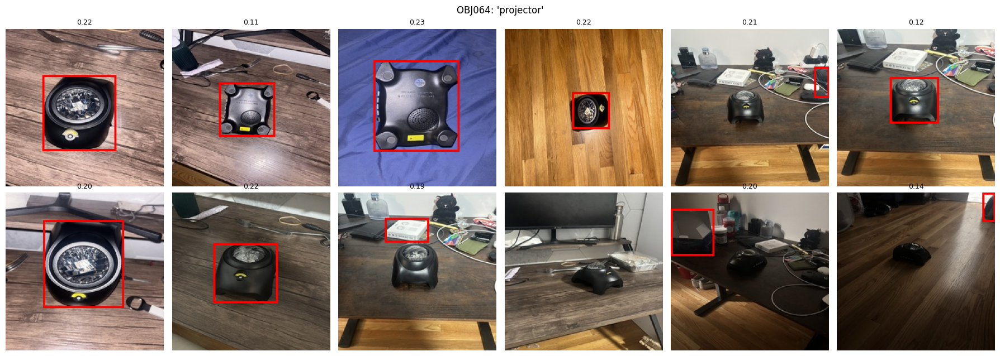

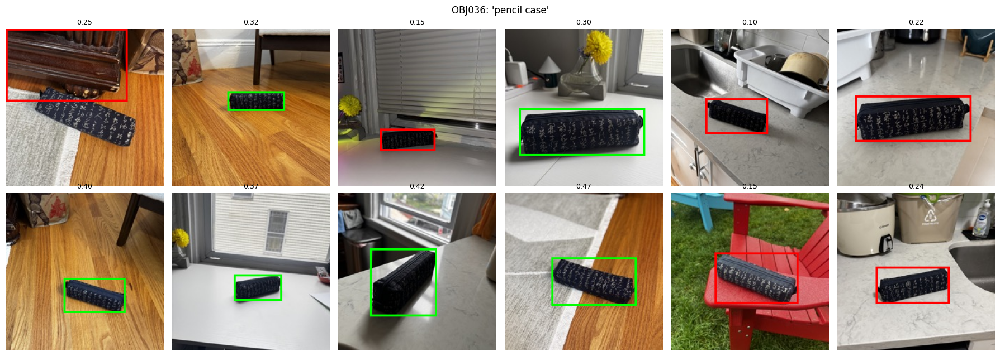

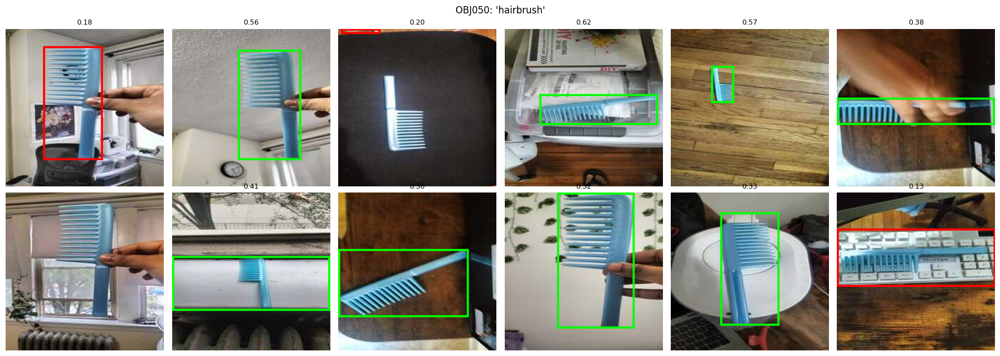

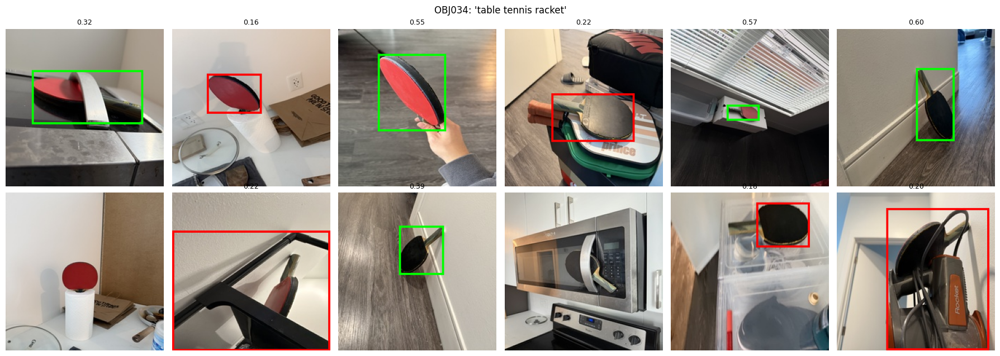

In [17]:
def show_boxes(c, n=12):
    """Show n photos of one object with its automatic box (green = kept, red = dropped)."""
    cid = classes.index(c)
    picks = random.Random(0).sample(files[cid], min(n, len(files[cid])))
    fig, ax = plt.subplots(2, (len(picks) + 1) // 2, figsize=(3 * ((len(picks) + 1) // 2), 6.5))
    for a, p in zip(ax.flat, picks):
        img = load224(p); d = ImageDraw.Draw(img); b = BOXES.get(str(p))
        if b:
            d.rectangle(b[:4], outline="lime" if b[4] >= KEEP else "red", width=3)
            a.set_title(f"{b[4]:.2f}", fontsize=9)
        a.imshow(img); a.axis("off")
    plt.suptitle(f"{c}: '{prompt_for(c)}'"); plt.tight_layout(); plt.show()

# look at the weakest objects first
for c in summ.object_id.head(4):
    show_boxes(c)

If an object's boxes land on the wrong thing, give it a better description and relabel just that object, for example:

```python
PROMPT_FIX["OBJ057"] = "blue metal water bottle"
label_classes(["OBJ057"], force=True)
show_boxes("OBJ057")
```

Then rerun the summary cell.

1/1 OBJ057


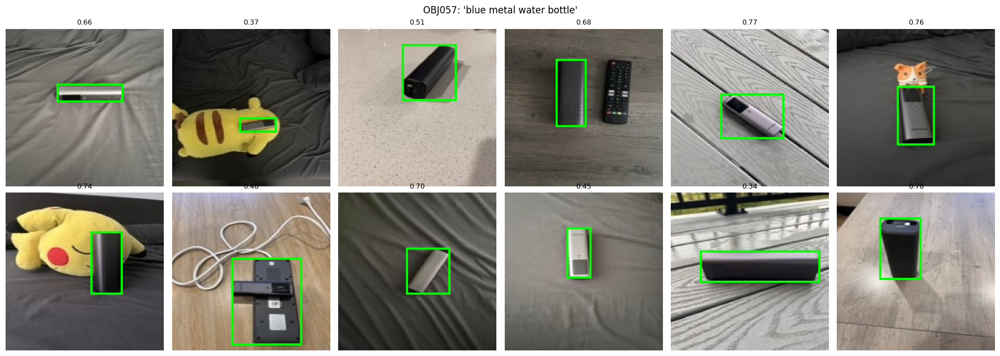

In [18]:
PROMPT_FIX["OBJ057"] = "blue metal water bottle"
label_classes(["OBJ057"], force=True)
show_boxes("OBJ057")

In [ ]:
# relabel objects after editing PROMPT_FIX (leave the list empty if nothing needs fixing)
FIX = []
if FIX:
    label_classes(FIX, force=True)
    summ = summary()
    for c in FIX:
        show_boxes(c)

### Building the multi-object dataset

Same idea as before (grids of 224×224 photos), but each label is now the object's own box, scaled and shifted into its cell.

- Layouts: 35% 2x2, 35% 3x3, 15% single photo (1x1), 7.5% 2x3, 7.5% 3x2.
- About a quarter of the grids leave 1–2 cells empty.
- Train/val/test split (70/15/15) on the original photos before making grids, so no photo is in both training and testing.
- Training-only augmentation: horizontal flip (box flipped too), brightness, and shrinking a tile inside its cell (box scaled too).
- Photos without a confident box are left out.

2000 images total. The requirement is 100 per student (400 minimum for our team of four).

In [19]:
N_IMAGES = 2000
OUT = Path("/content/dataset")
layouts = [(1, 1), (2, 2), (3, 3), (2, 3), (3, 2)]
layout_w = [0.15, 0.35, 0.35, 0.075, 0.075]
split_frac = {"train": 0.70, "val": 0.15, "test": 0.15}

def good(p):
    b = BOXES.get(str(p))
    return b is not None and b[4] >= KEEP and (b[2] - b[0]) > 4 and (b[3] - b[1]) > 4

rng = random.Random(SEED)
pools = {s: [] for s in split_frac}
for imgs in files:
    imgs = [p for p in imgs if good(p)]
    rng.shuffle(imgs)
    a = int(len(imgs) * 0.70)
    b = a + int(len(imgs) * 0.15)
    pools["train"].append(imgs[:a])
    pools["val"].append(imgs[a:b])
    pools["test"].append(imgs[b:])
print({s: sum(len(x) for x in v) for s, v in pools.items()})

def get_tile(path, augment):
    img = load224(path)
    x1, y1, x2, y2 = BOXES[str(path)][:4]
    if augment:
        if rng.random() < 0.5:
            img = img.transpose(Image.FLIP_LEFT_RIGHT)
            x1, x2 = TILE - x2, TILE - x1
        if rng.random() < 0.5:
            img = ImageEnhance.Brightness(img).enhance(rng.uniform(0.75, 1.25))
    return img, (x1, y1, x2, y2)

def make_grid(pool, augment=False, layout=None, allow_empty=True):
    rows, cols = layout if layout else rng.choices(layouts, weights=layout_w)[0]
    n_cells = rows * cols
    W, H = cols * TILE, rows * TILE
    canvas = Image.new("RGB", (W, H), (114, 114, 114))

    n_obj = n_cells
    if allow_empty and n_cells >= 4 and rng.random() < 0.25:
        n_obj = max(2, n_cells - rng.randint(1, 2))
    cells = rng.sample(range(n_cells), n_obj)
    available = [c for c in range(len(pool)) if pool[c]]
    cls_ids = rng.sample(available, n_obj)

    labels = []
    for cell, cid in zip(cells, cls_ids):
        tile, (x1, y1, x2, y2) = get_tile(rng.choice(pool[cid]), augment)
        r, c = divmod(cell, cols)
        x, y, s = c * TILE, r * TILE, TILE
        if augment and rng.random() < 0.3:
            s = int(TILE * rng.uniform(0.7, 0.95))
            tile = tile.resize((s, s))
            x += rng.randint(0, TILE - s)
            y += rng.randint(0, TILE - s)
        canvas.paste(tile, (x, y))
        k = s / TILE
        bx1, by1, bx2, by2 = x + x1 * k, y + y1 * k, x + x2 * k, y + y2 * k
        labels.append(f"{cid} {(bx1 + bx2) / 2 / W:.6f} {(by1 + by2) / 2 / H:.6f} "
                      f"{(bx2 - bx1) / W:.6f} {(by2 - by1) / H:.6f}")
    return canvas, labels

if OUT.exists():
    shutil.rmtree(OUT)
for split, frac in split_frac.items():
    (OUT / "images" / split).mkdir(parents=True)
    (OUT / "labels" / split).mkdir(parents=True)
    for i in range(int(N_IMAGES * frac)):
        img, labels = make_grid(pools[split], augment=(split == "train"))
        img.save(OUT / "images" / split / f"{split}_{i:05d}.jpg", quality=95)
        (OUT / "labels" / split / f"{split}_{i:05d}.txt").write_text("\n".join(labels) + "\n")
    print(split, int(N_IMAGES * frac))

with open(OUT / "data.yaml", "w") as f:
    f.write(f"path: {OUT}\ntrain: images/train\nval: images/val\ntest: images/test\n")
    f.write(f"nc: {len(classes)}\nnames:\n")
    for i, c in enumerate(classes):
        f.write(f'  {i}: "{display_name(c)}"\n')

os.makedirs(OUT / "examples", exist_ok=True)
for lay in [(1, 1), (2, 2), (3, 3)]:
    img, _ = make_grid(pools["train"], layout=lay, allow_empty=False)
    img.save(OUT / "examples" / f"sample_{lay[0]}x{lay[1]}.jpg", quality=95)

{'train': 4439, 'val': 933, 'test': 1024}
train 1400
val 300
test 300


Label check: the red boxes should sit tightly on each object.

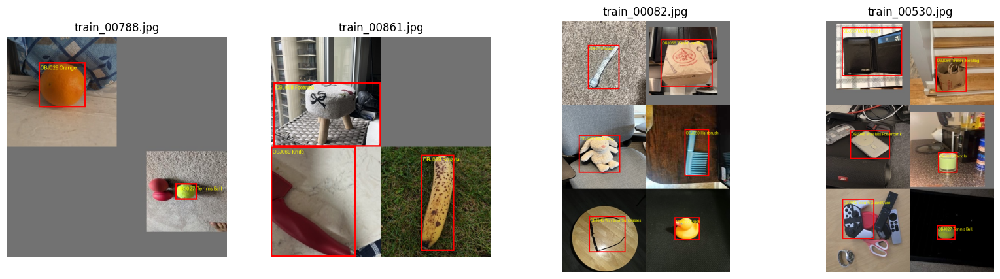

In [20]:
def draw_labels(img_path):
    img = Image.open(img_path).convert("RGB"); d = ImageDraw.Draw(img); W, H = img.size
    lbl = OUT / "labels" / img_path.parent.name / (img_path.stem + ".txt")
    for line in lbl.read_text().strip().split("\n"):
        cid, cx, cy, w, h = line.split()
        cx, cy, w, h = float(cx) * W, float(cy) * H, float(w) * W, float(h) * H
        d.rectangle([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], outline="red", width=3)
        d.text((cx - w / 2 + 4, cy - h / 2 + 4), display_name(classes[int(cid)]), fill="yellow")
    return img

sample = random.Random(0).sample(sorted((OUT / "images" / "train").glob("*.jpg")), 4)
fig, ax = plt.subplots(1, 4, figsize=(20, 5))
for a, p in zip(ax, sample):
    a.imshow(draw_labels(p)); a.set_title(p.name); a.axis("off")
plt.show()

### Training

Same settings as our earlier run: YOLOv8s pretrained on COCO, image size 672, up to 60 epochs, early stopping (patience 15), mosaic 0.5.

In [21]:
import time
from ultralytics import YOLO

t0 = time.time()
model = YOLO("yolov8s.pt")
model.train(
    data=str(OUT / "data.yaml"), epochs=60, imgsz=672, batch=16, patience=15,
    mosaic=0.5, close_mosaic=10, fliplr=0.5, seed=SEED,
    project="/content/runs", name="yolov8s_tight", exist_ok=True,
)
train_time = (time.time() - t0) / 60
run_dir = Path(model.trainer.save_dir)
print(f"training took {train_time:.1f} min")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, free

### Evaluation on the test split

In [22]:
best = YOLO(str(run_dir / "weights" / "best.pt"))
metrics = best.val(data=str(OUT / "data.yaml"), split="test", imgsz=672,
                   project="/content/runs", name="test", exist_ok=True)
test_dir = Path(metrics.save_dir)
print(f"mAP50     {metrics.box.map50:.4f}")
print(f"mAP50-95  {metrics.box.map:.4f}")
print(f"precision {metrics.box.mp:.4f}")
print(f"recall    {metrics.box.mr:.4f}")

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,153,835 parameters, 0 gradients, 28.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 27.6±16.2 MB/s, size: 102.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/dataset/labels/test... 300 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 300/300 602.1it/s 0.5s
val: New cache created: /content/dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 2.6it/s 7.4s
                   all        300       1546      0.896      0.888      0.916      0.859
     OBJ001 Basketball         11         11      0.891          1      0.995      0.986
   OBJ002 Water Bottle         24         24      0.974          1      0.995      0.995
       OBJ003 Noteb

In [23]:
per_class = pd.DataFrame({
    "object": [best.names[int(i)] for i in metrics.box.ap_class_index],
    "AP50": metrics.box.ap50,
    "AP50-95": metrics.box.ap,
}).sort_values("AP50-95")
per_class.to_csv("/content/runs/per_class_ap.csv", index=False)
print("lowest:"); print(per_class.head(5).to_string(index=False))
print("\nhighest:"); print(per_class.tail(5).to_string(index=False))

lowest:
              object     AP50  AP50-95
   OBJ060 Sleep Mask 0.309854 0.269866
OBJ010 Nike Sneakers 0.647259 0.478522
   OBJ014 Sunglasses 0.742672 0.535912
 OBJ013 Mobile Phone 0.585115 0.548959
        OBJ069 Knife 0.640000 0.612776

highest:
               object  AP50  AP50-95
  OBJ002 Water Bottle 0.995    0.995
OBJ005 Computer Mouse 0.995    0.995
     OBJ021 Toy Bunny 0.995    0.995
        OBJ029 Orange 0.995    0.995
   OBJ053 Moisturizer 0.995    0.995


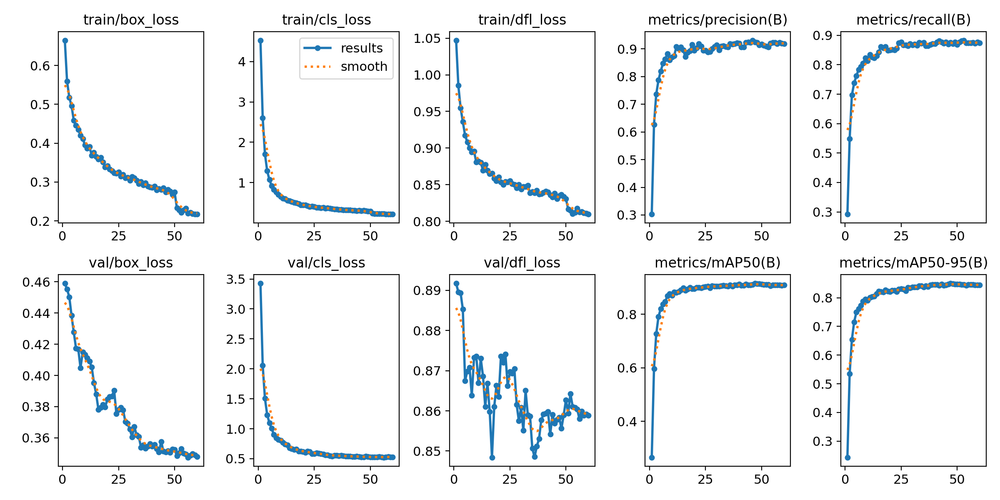

BoxPR_curve.png


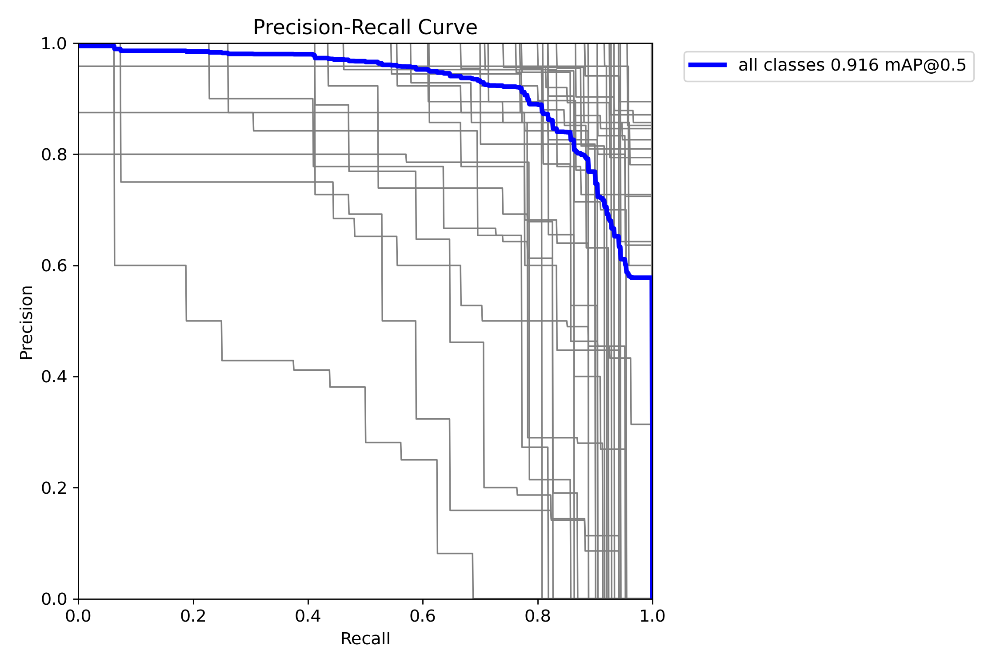

confusion_matrix_normalized.png


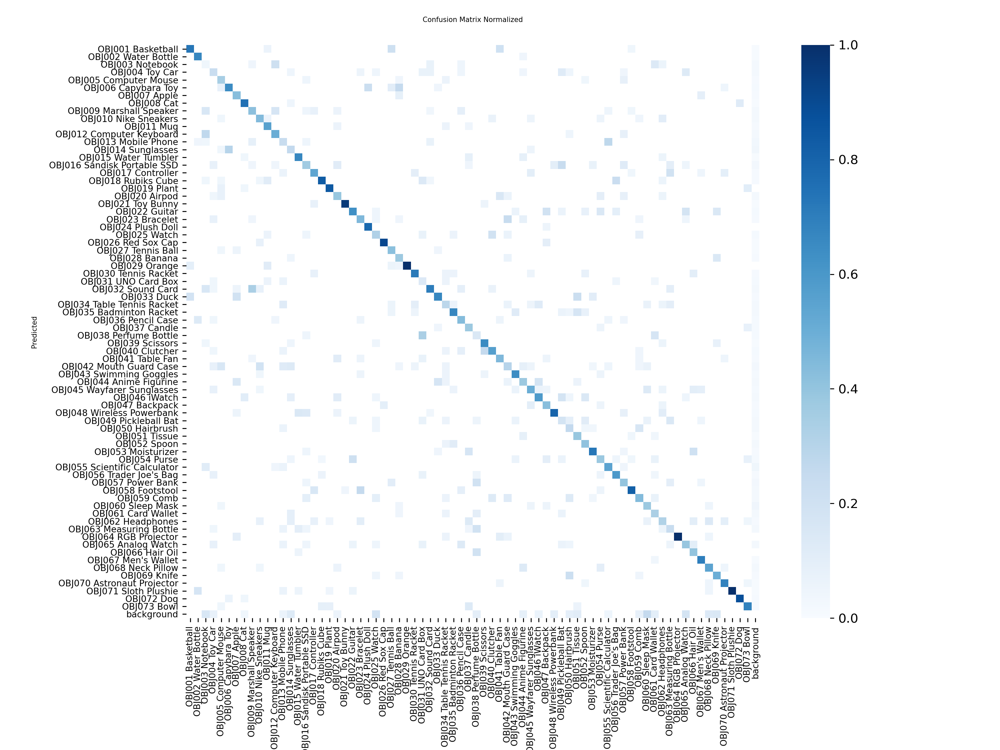

In [24]:
from IPython.display import Image as show_img, display
display(show_img(filename=str(run_dir / "results.png"), width=900))
for p in sorted(test_dir.glob("*PR_curve.png")) + sorted(test_dir.glob("confusion_matrix_normalized.png")):
    print(p.name); display(show_img(filename=str(p), width=800))

### Sample predictions


0: 672x672 1 OBJ008 Cat, 1 OBJ018 Rubiks Cube, 1 OBJ044 Anime Figurine, 1 OBJ061 Card Wallet, 14.2ms
1: 672x672 1 OBJ004 Toy Car, 1 OBJ007 Apple, 1 OBJ012 Computer Keyboard, 1 OBJ026 Red Sox Cap, 1 OBJ063 Measuring Bottle, 14.2ms
2: 672x672 1 OBJ007 Apple, 1 OBJ012 Computer Keyboard, 1 OBJ036 Pencil Case, 1 OBJ037 Candle, 1 OBJ047 Backpack, 1 OBJ050 Hairbrush, 1 OBJ069 Knife, 1 OBJ073 Bowl, 14.2ms
3: 672x672 (no detections), 14.2ms
4: 672x672 (no detections), 14.2ms
5: 672x672 1 OBJ009 Marshall Speaker, 1 OBJ019 Plant, 1 OBJ022 Guitar, 1 OBJ039 Scissors, 1 OBJ047 Backpack, 14.2ms
6: 672x672 1 OBJ015 Water Tumbler, 1 OBJ024 Plush Doll, 1 OBJ027 Tennis Ball, 1 OBJ031 UNO Card Box, 1 OBJ044 Anime Figurine, 1 OBJ066 Hair Oil, 1 OBJ073 Bowl, 14.2ms
7: 672x672 1 OBJ020 Airpod, 1 OBJ050 Hairbrush, 14.2ms
8: 672x672 1 OBJ005 Computer Mouse, 1 OBJ032 Sound Card, 1 OBJ058 Footstool, 1 OBJ061 Card Wallet, 14.2ms
9: 672x672 1 OBJ006 Capybara Toy, 1 OBJ009 Marshall Speaker, 1 OBJ014 Sunglasses, 1 

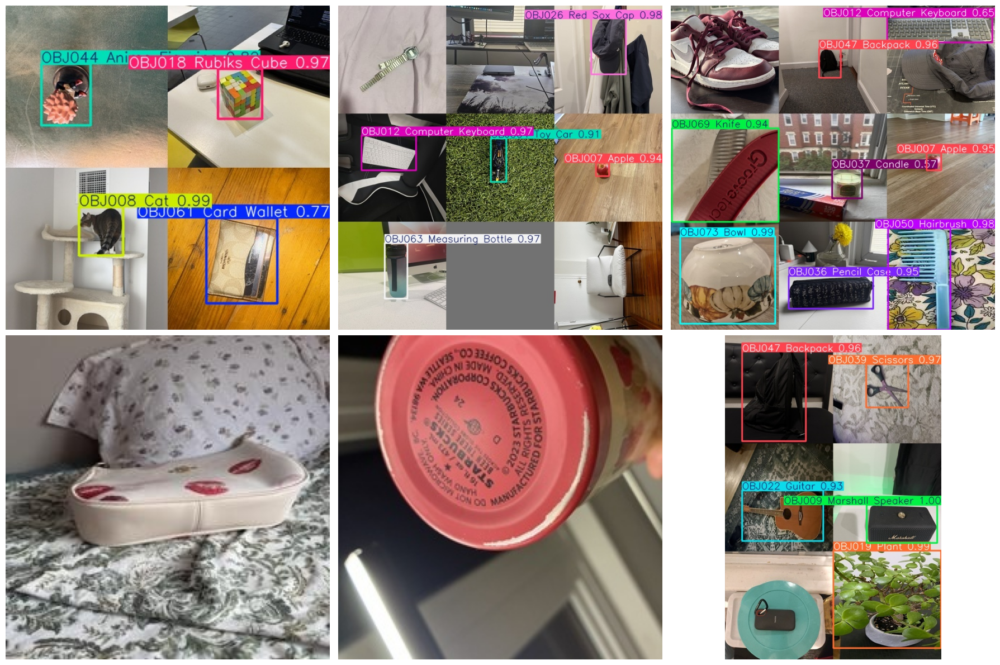

In [25]:
test_imgs = sorted((OUT / "images" / "test").glob("*.jpg"))[:20]
preds = best.predict([str(p) for p in test_imgs], imgsz=672, conf=0.4, agnostic_nms=True, save=True,
                     project="/content/runs", name="predictions", exist_ok=True)
pred_dir = Path(preds[0].save_dir)
fig, ax = plt.subplots(2, 3, figsize=(18, 12))
for a, p in zip(ax.flat, sorted(pred_dir.glob("*.jpg"))[:6]):
    a.imshow(Image.open(p)); a.axis("off")
plt.tight_layout(); plt.show()

### Single-object check

Every held-out test photo is passed in on its own. We check the predicted Object ID, and how well the predicted box overlaps the reference box (IoU). We compare passing the photo in directly with placing it in the corner of a 2x2-sized gray canvas, which worked better in our earlier run.

In [26]:
def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    return inter / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter + 1e-9)

def single_input(img, corner):
    if not corner:
        return img
    c = Image.new("RGB", (448, 448), (114, 114, 114)); c.paste(img, (0, 0)); return c

for corner in [False, True]:
    correct, total, ious = 0, 0, []
    for cid, imgs in enumerate(pools["test"]):
        for p in imgs:
            r = best.predict(single_input(load224(p), corner), imgsz=672, conf=0.05, agnostic_nms=True, verbose=False)[0]
            total += 1
            if len(r.boxes):
                k = int(r.boxes.conf.argmax())
                if int(r.boxes.cls[k]) == cid:
                    correct += 1
                    ious.append(iou(r.boxes.xyxy[k].tolist(), BOXES[str(p)][:4]))
    name = "2x2 corner" if corner else "direct"
    print(f"{name:10s}  ID accuracy {correct}/{total} = {correct / total:.3f}   mean IoU {sum(ious) / max(1, len(ious)):.3f}")

direct      ID accuracy 820/1024 = 0.801   mean IoU 0.821
2x2 corner  ID accuracy 976/1024 = 0.953   mean IoU 0.913


### Predict on a new image

OBJ044 Anime Figurine    0.99  (47, 84, 127, 133)


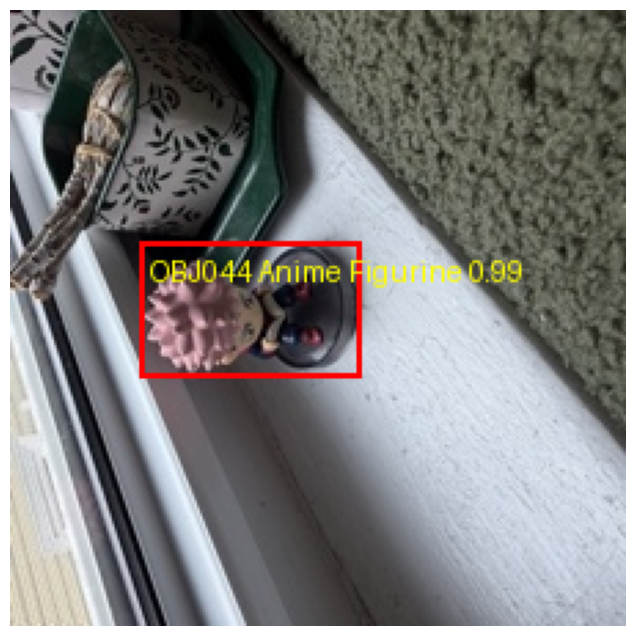

OBJ017 Controller        0.99  (511, 525, 610, 583)
OBJ011 Mug               0.98  (239, 447, 338, 608)
OBJ041 Table Fan         0.98  (483, 46, 607, 163)
OBJ056 Trader Joe's Bag  0.97  (59, 510, 133, 600)
OBJ071 Sloth Plushie     0.97  (229, 36, 399, 224)
OBJ031 UNO Card Box      0.97  (82, 99, 117, 119)
OBJ055 Scientific Calculator 0.96  (79, 315, 116, 366)
OBJ028 Banana            0.95  (511, 271, 624, 384)
OBJ013 Mobile Phone      0.91  (308, 302, 421, 363)
OBJ056 Trader Joe's Bag  0.56  (0, 496, 42, 668)


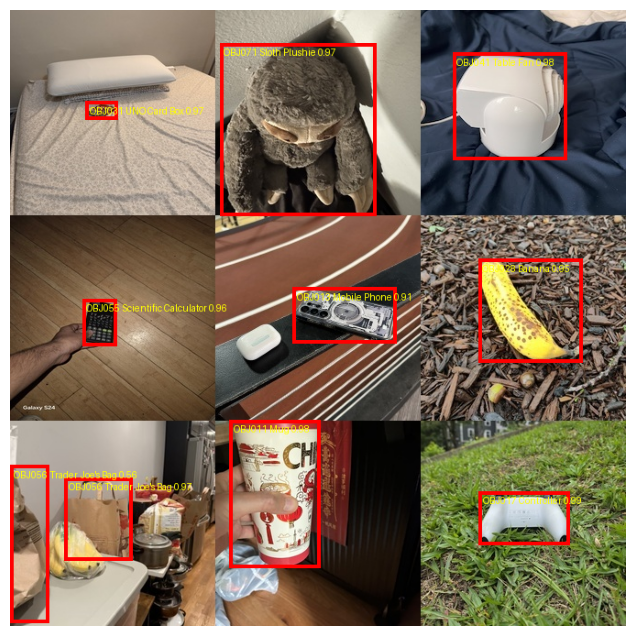

[('OBJ017 Controller',
  0.9867534041404724,
  (511.5093994140625,
   525.2562255859375,
   610.6309814453125,
   583.7532958984375)),
 ('OBJ011 Mug',
  0.9802097678184509,
  (239.99697875976562,
   447.0552673339844,
   338.2990417480469,
   608.1361083984375)),
 ('OBJ041 Table Fan',
  0.9775204062461853,
  (483.333740234375,
   46.60345458984375,
   607.0350341796875,
   163.76718139648438)),
 ("OBJ056 Trader Joe's Bag",
  0.9747821688652039,
  (59.84275817871094,
   510.5032043457031,
   133.97653198242188,
   600.193115234375)),
 ('OBJ071 Sloth Plushie',
  0.9740749597549438,
  (229.15333557128906, 36.22264099121094, 399.31982421875, 224.7771759033203)),
 ('OBJ031 UNO Card Box',
  0.9739786386489868,
  (82.91618347167969,
   99.99224853515625,
   117.04029846191406,
   119.5582275390625)),
 ('OBJ055 Scientific Calculator',
  0.9639121890068054,
  (79.24586486816406,
   315.20355224609375,
   116.54734802246094,
   366.04339599609375)),
 ('OBJ028 Banana',
  0.9482933878898621,
  (51

In [27]:
CORNER = True   # set to whichever input worked better in the single-object check

def detect(path, single=False, conf=0.4):
    orig = Image.open(path).convert("RGB")
    d = ImageDraw.Draw(orig)
    lw = max(2, orig.size[0] // 150)
    if single:
        w, h = orig.size; s = min(w, h); ox, oy = (w - s) // 2, (h - s) // 2
        sq = orig.crop((ox, oy, ox + s, oy + s)).resize((TILE, TILE))
        r = best.predict(single_input(sq, CORNER), imgsz=672, conf=0.05, agnostic_nms=True, verbose=False)[0]
        if not len(r.boxes):
            print("no object detected"); return
        k = int(r.boxes.conf.argmax())
        f = s / TILE
        x1, y1, x2, y2 = [v * f for v in r.boxes.xyxy[k].tolist()]
        x1, x2, y1, y2 = x1 + ox, x2 + ox, y1 + oy, y2 + oy
        found = [(best.names[int(r.boxes.cls[k])], float(r.boxes.conf[k]), (x1, y1, x2, y2))]
    else:
        r = best.predict(orig, imgsz=672, conf=conf, agnostic_nms=True, verbose=False)[0]
        found = [(best.names[int(b.cls)], float(b.conf), tuple(b.xyxy[0].tolist())) for b in r.boxes]
    for name, c, (x1, y1, x2, y2) in found:
        d.rectangle([x1, y1, x2, y2], outline="red", width=lw)
        d.text((x1 + 4, y1 + 4), f"{name} {c:.2f}", fill="yellow")
        print(f"{name:<24} {c:.2f}  ({int(x1)}, {int(y1)}, {int(x2)}, {int(y2)})")
    plt.figure(figsize=(8, 8)); plt.imshow(orig); plt.axis("off"); plt.show()
    return found

detect(OUT / "examples" / "sample_1x1.jpg", single=True)
detect(OUT / "examples" / "sample_3x3.jpg")

### Save results to Drive

In [28]:
shutil.copytree("/content/runs", RESULTS / "runs", dirs_exist_ok=True)
shutil.copytree(OUT / "examples", RESULTS / "examples", dirs_exist_ok=True)
shutil.copy(OUT / "data.yaml", RESULTS)
shutil.copy(run_dir / "weights" / "best.pt", RESULTS / "best.pt")
print("saved to", RESULTS)

saved to /content/drive/MyDrive/IE7615_M3_results
